## 0. SETUP

We use the venv from the tutorial and will install any additional dependencies here without modifying the provided requirements.txt. Mirroring the tutorial:


In [1]:
from keras.src.layers.preprocessing.benchmarks.image_preproc_benchmark import BATCH_SIZE
from keras.src.legacy_tf_layers.core import dropout
from networkx.algorithms.traversal import dfs_successors
from torch.utils.data import DataLoader
from transformers.models.bert.modeling_bert import BertEncoder
%load_ext autoreload
%autoreload 2

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

ModuleNotFoundError: No module named 'keras.src.layers.preprocessing.benchmarks'

In [1]:
# like the tutorial make part 1 modules importable
import sys
from pathlib import Path
 
root = Path.cwd().parent
sys.path.insert(0, str(root))

import part1
from part1 import clslib, experiment, loglin, smlp, analysis, utils, bpe

In [2]:
import numpy as np

results_folder = Path("./results")
results_folder.mkdir(parents=True, exist_ok=True)

# The order below fixes our integer<->name mapping for the whole project which is our deliberate choice
snli_outcome_space = clslib.NamedClasses(['entailment', 'neutral', 'contradiction'])
print(snli_outcome_space)

0: entailment, 1: neutral, 2: contradiction


## 1. Load dataset


In [3]:
from datasets import load_dataset

snli = load_dataset("stanfordnlp/snli")
print(snli)

DatasetDict({
    test: Dataset({
        features: ['premise', 'hypothesis', 'label'],
        num_rows: 10000
    })
    validation: Dataset({
        features: ['premise', 'hypothesis', 'label'],
        num_rows: 10000
    })
    train: Dataset({
        features: ['premise', 'hypothesis', 'label'],
        num_rows: 550152
    })
})


We inspect the dataset as follows:

In [4]:
ex = snli["train"][0]
print("Fields:", list(ex.keys()))
print("premise   :", ex["premise"])
print("hypothesis:", ex["hypothesis"])
print("label (id):", ex["label"])
print()
print("Label feature:", snli["train"].features["label"])

Fields: ['premise', 'hypothesis', 'label']
premise   : A person on a horse jumps over a broken down airplane.
hypothesis: A person is training his horse for a competition.
label (id): 1

Label feature: ClassLabel(names=['entailment', 'neutral', 'contradiction'], id=None)


It is important to check this mapping is in alignment with the one we chose to implement so we do not need to do any remappings. Confirmed!

## 1.1 Check for "Bad Data":

1. The HF card mentions that when human annotators could not agree on a label, they default to -1. We need to inspect them and drop them



In [5]:
from collections import Counter

for split in ["train", "validation", "test"]:
    counts = Counter(snli[split]["label"])
    n = len(snli[split])
    n_bad = counts.get(-1, 0)
    print(f"{split:11s} | total {n:>7d} | unlabeled(-1): {n_bad:>5d} | "
          f"dist (0/1/2): {counts.get(0,0)}/{counts.get(1,0)}/{counts.get(2,0)}")

train       | total  550152 | unlabeled(-1):   785 | dist (0/1/2): 183416/182764/183187
validation  | total   10000 | unlabeled(-1):   158 | dist (0/1/2): 3329/3235/3278
test        | total   10000 | unlabeled(-1):   176 | dist (0/1/2): 3368/3219/3237


Also immediate observation: class balance which supports using accuracy for a valid metric.


2. Check for empty strings, non-strings/None, exact duplicates and degenerate pairs

In [6]:
for split in ["train", "validation", "test"]:
    prem = snli[split]["premise"]
    hyp  = snli[split]["hypothesis"]
    n = len(prem)

    # non-string or None entries
    bad_type_p = sum(not isinstance(p, str) for p in prem)
    bad_type_h = sum(not isinstance(h, str) for h in hyp)

    # empty / whitespace-only after stripping
    empty_p = sum(isinstance(p, str) and p.strip() == "" for p in prem)
    empty_h = sum(isinstance(h, str) and h.strip() == "" for h in hyp)

    # premise identical to hypothesis (degenerate pair)
    identical = sum(p == h for p, h in zip(prem, hyp))

    print(f"{split:11s} | n={n:>7d} | "
          f"non-str p/h: {bad_type_p}/{bad_type_h} | "
          f"empty p/h: {empty_p}/{empty_h} | "
          f"premise==hypothesis: {identical}")

train       | n= 550152 | non-str p/h: 0/0 | empty p/h: 0/0 | premise==hypothesis: 309
validation  | n=  10000 | non-str p/h: 0/0 | empty p/h: 0/0 | premise==hypothesis: 4
test        | n=  10000 | non-str p/h: 0/0 | empty p/h: 0/0 | premise==hypothesis: 0


!! flag result: if premise and hypothesis are the exact same sentence, the logically correct label is entailment (a sentence trivially entails itself). Which tells us these are either correctly labeled entailment and harmless, or labeled something else, in which case they’re mislabeled or they’re the degenerate artifact cases and we have to handle them. check:

In [7]:
# What labels do the identical-pair examples carry?
from collections import Counter
identical_labels = [ex["label"] for ex in snli["train"]
    if ex["label"] != -1 and ex["premise"] == ex["hypothesis"]]
print(Counter(identical_labels))  # 0=entail, 1=neutral, 2=contradiction

Counter({0: 267, 1: 25, 2: 17})


- 267 of the 309 identical pairs are entailment (label 0) which is the logically correct label sinc a sentence entails itself. The25 neutral and 17 contradiction where premise and hypothesis are character-for-character identical, these are by definition label noise.
- Practical decision is to keep them all because 42 bad labels out of ~549k is ~0.008% thus statistically invisible to our models, so removing them changes no accuracy number we report.  
- Strategic note! If we do the headline extension about models exploiting shortcuts instead of doing inference, the single strongest shortcut imaginable is “premise and hypothesis share words → entailment,” and we have at the ready 267 examples where total overlap goes with entailment -> we have a ready overlap heuristic. When we later show that overlap-based features push toward entailment, these identical pairs are the limiting case of exactly that pattern.  

3. Because BPE pretokenizer splits on whitespace, this means a "sentence" that tokenizes to nothing (e.g. only punctuation/whitespace) would produce an all-zero feature vectorso we check the extremes of length so we know the range we're dealing with. ie we are making the assumption that each text tokenizes to at least one token so we have to confirm 

In [8]:
import numpy as np

for split in ["train"]:
    lens_p = np.array([len(p.split()) for p in snli[split]["premise"]])
    lens_h = np.array([len(h.split()) for h in snli[split]["hypothesis"]])
    print(f"premise words   : min={lens_p.min()}, median={int(np.median(lens_p))}, max={lens_p.max()}")
    print(f"hypothesis words: min={lens_h.min()}, median={int(np.median(lens_h))}, max={lens_h.max()}")
    print("premises with 0 words   :", int((lens_p == 0).sum()))
    print("hypotheses with 0 words :", int((lens_h == 0).sum()))

premise words   : min=2, median=12, max=78
hypothesis words: min=1, median=7, max=56
premises with 0 words   : 0
hypotheses with 0 words : 0


## 1.2 Stratified Subsampling Decision:



We train on a stratified 40k subsample of SNLI's ~549k training pairs rather than the
full set. The size sits at the intersection of three levers.

**1. Statistical resolution (lower bound).** Our Bayesian comparison operates on
per-fold accuracies, so each validation fold must be large enough that its accuracy
estimate isn't dominated by sampling noise,otherwise the ROPE verdicts become
unresolvable. With 40k and 5-fold CV, each validation fold holds ~8k examples. At an
expected accuracy around 0.75, the standard error on fold accuracy is
√(0.75·0.25 / 8000) ≈ 0.0048 so about half a percentage point, the same order as our
0.005 ROPE. Fold-level noise should be comparable
to or smaller than the ROPE. If we go lower, at only 1k
per fold for example the SE would be ≈ 0.014, roughly three times the ROPE, and most comparisons
would return "can't tell."

**2. Computational tractability (upper bound).** The grid is 9 systems × 5 folds ×
several seeds, plus extensions, and the MLP dominates runtime. The tutorial reports
~20 min for a single 5-fold MLP run on 120k AG News examples and at ~1/3 the data, 40k
puts an MLP run near 6–8 min and the full grid around an afternoon per seed. The full
~550k set would push repeated runs into overnight territory, which is impractical.

**3. Diminishing returns (the SNLI-specific argument).** Bowman et al. (2015) show in
their learning-curve analysis that simple models (feature-rich lexicalized classifiers)
flatten out well before the full corpus, while neural models are the ones that keep improving
with more data. Since our required grid uses simple models (log-linear, shallow MLP),
40k places us on the flat part of their learning curve: the remaining ~500k examples
would add little accuracy for these model classes while costing ~10× the compute.

**Together:** statistics says don't go far below ~20–40k (or the ROPE can't resolve
anything), compute says don't go far above ~50k (or the grid stops being re-runnable),
and the SNLI learning curve says above ~40k we pay for accuracy these simple models
won't gain. 40k is where all three agree.

IF time permits we can include the learning-curve experiment (grid run at 10k / 20k /
40k) testing it directly, serving simultaneously as empirical justification of the
working-set size, a replication of a published SNLI finding, and the
sample-size sensitivity check our Bayesian analysis needs.

In [9]:
from sklearn.model_selection import train_test_split

WORKING_SET_SIZE = 40_000
SUBSAMPLE_SEED = 0  # fixed for reproducibility 

# Drop the -1 examples keep (premise, hypothesis, label).
# train_pairs_all = [
#     ((ex["premise"], ex["hypothesis"]), ex["label"])
#     for ex in snli["train"]
#     if ex["label"] != -1
# ]

train_pairs_all = []
for ex in snli["train"]:
    if ex["label"] == -1:
        continue
    if ex["premise"] == ex["hypothesis"] and ex['label'] != 0:
        continue
    train_pairs_all.append(((ex["premise"], ex["hypothesis"]), ex["label"]))


# Stratified subsample to the working-set size (preserves the balanced label dist).
X = [ph for ph, _ in train_pairs_all]
y = [lab for _, lab in train_pairs_all]

X_work, _, y_work, _ = train_test_split(
    X, y,
    train_size=WORKING_SET_SIZE,
    stratify=y,
    random_state=SUBSAMPLE_SEED,
)

# Reassemble into the ((premise, hypothesis), label) list we'll feed to CV.
working_set = list(zip(X_work, y_work))

#check: size + label distribution preserved.
from collections import Counter
print(f"Working set size: {len(working_set)}")
print("Label dist (0/1/2):", dict(sorted(Counter(y_work).items())))

Working set size: 40000
Label dist (0/1/2): {0: 13356, 1: 13306, 2: 13338}


In [10]:
import torch
from transformers import AutoTokenizer, AutoModel

bert_name = "google-bert/bert-base-uncased"
bert_tokenizer = AutoTokenizer.from_pretrained(bert_name)
bert_model = AutoModel.from_pretrained(bert_name)

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
bert_model.to(device)

BertModel(
  (embeddings): BertEmbeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (token_type_embeddings): Embedding(2, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (encoder): BertEncoder(
    (layer): ModuleList(
      (0-11): 12 x BertLayer(
        (attention): BertAttention(
          (self): BertSdpaSelfAttention(
            (query): Linear(in_features=768, out_features=768, bias=True)
            (key): Linear(in_features=768, out_features=768, bias=True)
            (value): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (output): BertSelfOutput(
            (dense): Linear(in_features=768, out_features=768, bias=True)
            (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
            (dropout): Dropout(p=0.1, inplace=False

In [11]:
device

device(type='mps')

In [13]:
# Embed everything
BATCH_SIZE = 64
first_sentences = [example[0] for example in X_work]
second_sentences = [example[1] for example in X_work]

labels = torch.tensor(y_work, dtype=torch.int64)

chunks = []
with torch.no_grad():
    for i in range(0, len(first_sentences), BATCH_SIZE):
        encoding = bert_tokenizer(
            first_sentences[i:i + BATCH_SIZE],
            second_sentences[i:i + BATCH_SIZE],
            padding=True,
            truncation=True,
            return_tensors="pt",
        )
        encoding = encoding.to(device)
        out = bert_model(**encoding)
        # chunks.append(out.pooler_output.cpu())  # out.last_hidden_state[:, 0, :] - pure [CLS] token
        chunks.append(out.last_hidden_state[:, 0, :].cpu())
# embeddings = out.pooler_output  # out.last_hidden_state[:, 0, :]
embeddings = torch.cat(chunks)

# torch.save(embeddings, results_folder / "bert_pooler_embeddings.pt")
torch.save(embeddings, results_folder / "bert_hidden_embeddings.pt")

In [14]:
embeddings.shape

torch.Size([40000, 768])

In [15]:
device

device(type='mps')

In [16]:
def train_dense_model(train_loader, val_loader, model, optimizer, 
                      save_to, criterion, num_epochs=20, device=torch.device("cpu")):
    
    if isinstance(device, str):
        device = torch.device(device)
    
    
    metrics = []
    print("Training...")
    best_val_loss = np.inf
    best_preds = []
    best_epoch = 0
    for epoch in range(num_epochs):
        train_metrics = smlp.train_one_epoch(model, train_loader, optimizer, criterion, device=device)
        val_metrics, preds = smlp.evaluate(model, val_loader, criterion, device)
        
        metrics.append({"train_metrics": train_metrics, "val_metrics": val_metrics})
        
        print(
            f"Epoch {epoch + 1:02d} | "
            f"train loss: {train_metrics['loss']:.4f} | "
            f"train acc: {train_metrics['accuracy']:.4f} | "
            f"val loss: {val_metrics['loss']:.4f} | "
            f"val acc: {val_metrics['accuracy']:.4f}"
            )
        
        # Saving the best model according to validation loss
        if val_metrics["loss"] <= best_val_loss:
            best_val_loss = val_metrics["loss"]
            torch.save(model.state_dict(), f"{save_to}.pt")
            best_epoch = epoch
            best_preds = preds
    return metrics, best_epoch, best_preds
    

In [17]:
import importlib
importlib.reload(smlp)

EPOCH_NUM = 20
NUM_FOLDS = 5

In [18]:
def cross_val_experiment(model_name, input_dim, hidden_dim, dropout, learning_rate, weight_decay):
    runs = []
    if model_name == 'bert_mlp_pooler_emb':
         embeddings = torch.load(results_folder / "bert_pooler_embeddings.pt")
    else:
         embeddings = torch.load(results_folder / "bert_hidden_embeddings.pt")

    for seed in seeds:
        losses, accuracies, models, predictions, best_epochs = {}, {}, {}, {}, {}
        folds = experiment.cross_validation_split(working_set, k=NUM_FOLDS, seed=seed)
        for i in folds.keys():
            fold = folds[i]
            train_loader = DataLoader(TensorDataset(
                embeddings[fold['training_ids']], labels[fold['training_ids']]),
                batch_size=BATCH_SIZE * 2,
                shuffle=True
            )
            val_loader = DataLoader(TensorDataset(
                embeddings[list(fold['validation_ids'])], labels[list(fold['validation_ids'])]),
                batch_size=BATCH_SIZE * 2,
            )
            
            mlp_args = {
                    'input_dim': input_dim, 
                    'hidden_dim': hidden_dim, 
                    'num_classes': len(snli_outcome_space), 
                    'dropout': dropout,
                }
            
            path = results_folder / model_name / f'seed-{seed}' / f'fold-{i}' / 'model'
            path.parent.mkdir(parents=True, exist_ok=True)
            with open(f'{path}.json', 'w', encoding="utf-8") as f:
                json.dump(mlp_args, f, indent=2, ensure_ascii=False)
                
            torch.manual_seed(seed)
            if model_name == 'bert_logistic':
                mlp_model = smlp.LogisticRegression(input_dim, len(snli_outcome_space))
            else:
                mlp_model = smlp.MLP(input_dim, hidden_dim, len(snli_outcome_space), dropout)
                
            mlp_model.to(device)
            optimizer = torch.optim.AdamW(mlp_model.parameters(), lr=learning_rate, weight_decay=weight_decay)
            criterion = nn.NLLLoss()
            
            metrics, best_epoch, predictions[i] = train_dense_model(train_loader, val_loader, mlp_model, optimizer, path, criterion, EPOCH_NUM, device)
            models[i] = path
            accuracies[i] = metrics[best_epoch]['val_metrics']['accuracy']
            losses[i] = {
                'train': [metrics[epoch]['train_metrics']['loss'] for epoch in range(EPOCH_NUM)],
                'val': [metrics[epoch]['val_metrics']['loss'] for epoch in range(EPOCH_NUM)],
            }
            best_epochs[i] = best_epoch
        run = {
            'seed': seed,
            'models': models,
            'predictions': predictions,
            'losses': losses,
            'accuracies': accuracies,
            'best_epochs': best_epochs,
        }
        runs.append(run)
        torch.save(run, results_folder / model_name / f'seed-{seed}' / 'run.pt')
    return runs
    

In [19]:
import json
from torch import nn
from torch.utils.data import TensorDataset
from torch.utils.data import DataLoader
import part1.experiment
import part1.smlp

seeds = [0, 3, 5]

EPOCH_NUM = 20
NUM_FOLDS = 5
input_dim = bert_model.config.hidden_size
hidden_dim = input_dim // 4
dropout = 0.2
learning_rate = 0.001
weight_decay = 0.0001

model_names = ['bert_mlp_hid_emb', 'bert_mlp_pooler_emb', 'bert_logistic']
classifiers = {model_name: [] for model_name in model_names}

for model_name in model_names:
    print(model_name)
    runs = cross_val_experiment(model_name, input_dim, hidden_dim, dropout, learning_rate, weight_decay)
    classifiers[model_name] = runs

bert_mlp_hid_emb
Training...


/var/folders/gf/dddrvhz17pn7_4ztl2xtcj7h0000gn/T/ipykernel_80341/3443313808.py:6: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  embeddings = torch.load(results_folder / "ber

Epoch 01 | train loss: 0.9406 | train acc: 0.5464 | val loss: 0.8789 | val acc: 0.5964
Epoch 02 | train loss: 0.8512 | train acc: 0.6112 | val loss: 0.8343 | val acc: 0.6265
Epoch 03 | train loss: 0.8231 | train acc: 0.6296 | val loss: 0.7993 | val acc: 0.6442
Epoch 04 | train loss: 0.7995 | train acc: 0.6423 | val loss: 0.7925 | val acc: 0.6459
Epoch 05 | train loss: 0.7896 | train acc: 0.6470 | val loss: 0.7988 | val acc: 0.6342
Epoch 06 | train loss: 0.7766 | train acc: 0.6548 | val loss: 0.7880 | val acc: 0.6440
Epoch 07 | train loss: 0.7667 | train acc: 0.6615 | val loss: 0.7753 | val acc: 0.6535
Epoch 08 | train loss: 0.7675 | train acc: 0.6582 | val loss: 0.7663 | val acc: 0.6617
Epoch 09 | train loss: 0.7554 | train acc: 0.6667 | val loss: 0.7626 | val acc: 0.6629
Epoch 10 | train loss: 0.7503 | train acc: 0.6708 | val loss: 0.7802 | val acc: 0.6540
Epoch 11 | train loss: 0.7407 | train acc: 0.6727 | val loss: 0.7615 | val acc: 0.6701
Epoch 12 | train loss: 0.7338 | train acc: 

/var/folders/gf/dddrvhz17pn7_4ztl2xtcj7h0000gn/T/ipykernel_80341/3443313808.py:4: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  embeddings = torch.load(results_folder / "ber

Epoch 01 | train loss: 1.0921 | train acc: 0.3766 | val loss: 1.0775 | val acc: 0.3986
Epoch 02 | train loss: 1.0764 | train acc: 0.3993 | val loss: 1.0676 | val acc: 0.4194
Epoch 03 | train loss: 1.0730 | train acc: 0.4037 | val loss: 1.0668 | val acc: 0.4150
Epoch 04 | train loss: 1.0712 | train acc: 0.4063 | val loss: 1.0643 | val acc: 0.4104
Epoch 05 | train loss: 1.0688 | train acc: 0.4094 | val loss: 1.0668 | val acc: 0.4032
Epoch 06 | train loss: 1.0665 | train acc: 0.4110 | val loss: 1.0574 | val acc: 0.4211
Epoch 07 | train loss: 1.0665 | train acc: 0.4101 | val loss: 1.0547 | val acc: 0.4238
Epoch 08 | train loss: 1.0632 | train acc: 0.4181 | val loss: 1.0540 | val acc: 0.4216
Epoch 09 | train loss: 1.0581 | train acc: 0.4201 | val loss: 1.0533 | val acc: 0.4209
Epoch 10 | train loss: 1.0605 | train acc: 0.4194 | val loss: 1.0590 | val acc: 0.4114
Epoch 11 | train loss: 1.0577 | train acc: 0.4232 | val loss: 1.0482 | val acc: 0.4299
Epoch 12 | train loss: 1.0576 | train acc: 

In [20]:
# bert_runs = [torch.load(results_folder / 'bert_mlp' / f'seed-{s}' / 'run.pt', weights_only=False) for s in seeds]

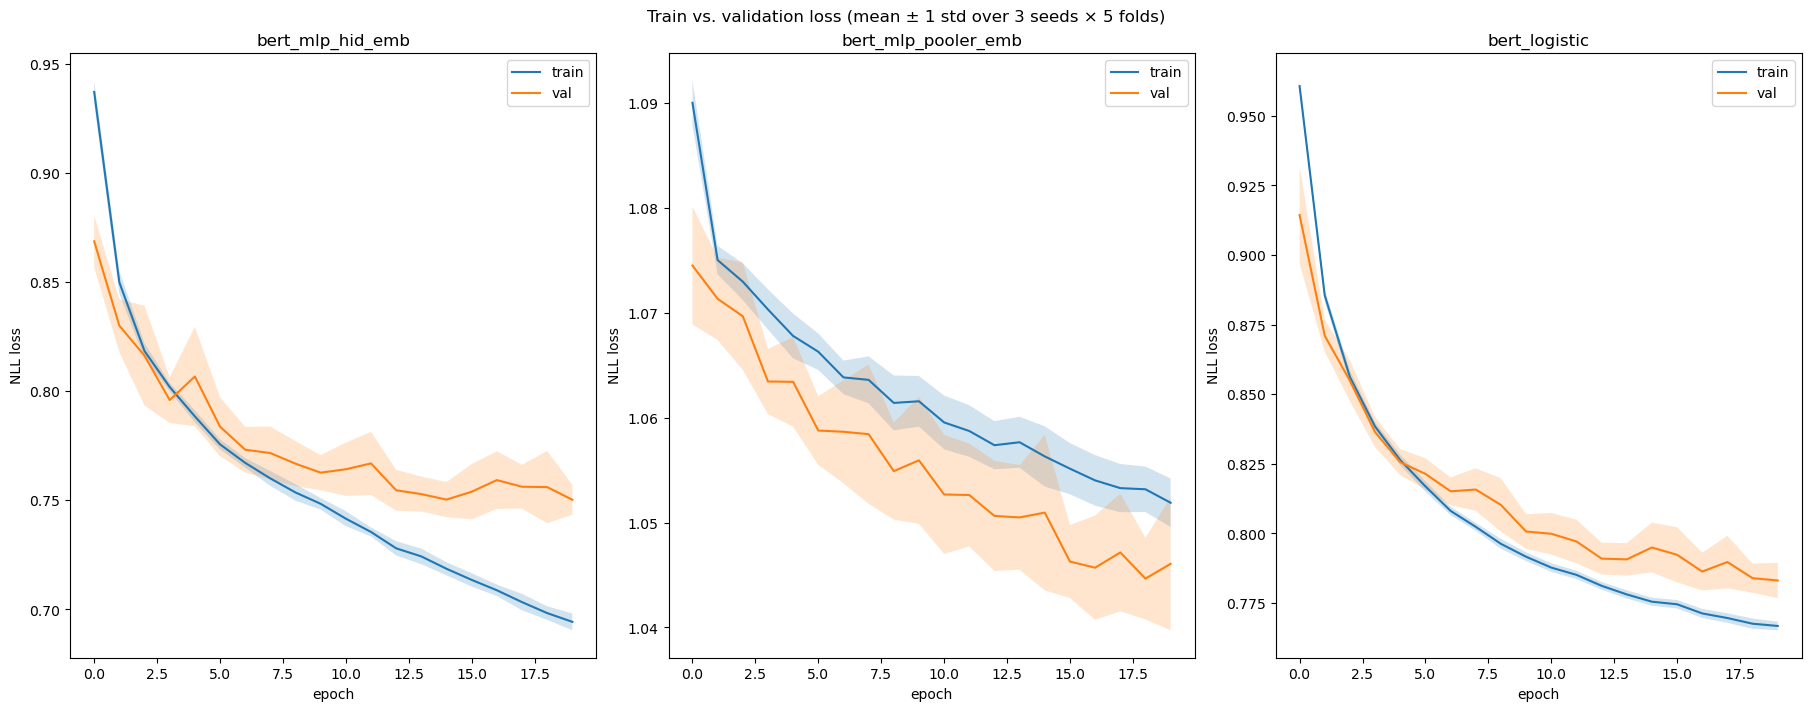

In [36]:
from matplotlib import pyplot as plt


def plot_mean_losses(runs, model_name, ax):
      train = np.array([fold['train'] for run in runs for fold in run['losses'].values()])
      val = np.array([fold['val'] for run in runs for fold in run['losses'].values()])
      epochs = np.arange(train.shape[1])

      for curves, label in [(train, 'train'), (val, 'val')]:
          mean, std = curves.mean(axis=0), curves.std(axis=0)
          ax.plot(epochs, mean, label=label)
          ax.fill_between(epochs, mean - std, mean + std, alpha=0.2)

      ax.set_title(model_name)
      ax.set_xlabel('epoch')
      ax.set_ylabel('NLL loss')
      ax.legend()

fig, axes = plt.subplots(1, len(model_names), figsize=(6 * len(model_names), 7), layout='constrained')
for a, model_name in zip(axes, model_names):
  plot_mean_losses(classifiers[model_name], model_name, a)
fig.suptitle('Train vs. validation loss (mean ± 1 std over 3 seeds × 5 folds)')
plt.show()


In [37]:
def load_results(model_name, seeds):
    return [torch.load(results_folder / model_name / f'seed-{s}' / 'run.pt', weights_only=False) for s in seeds]

# classifiers = {model_name: load_results(model_name, seeds) for model_name in model_names}


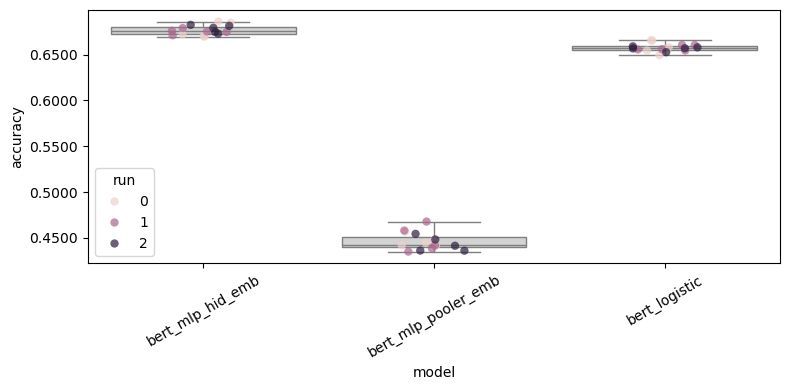

In [38]:
part1.analysis.plot_box_and_points(part1.analysis.make_data_frame(classifiers))

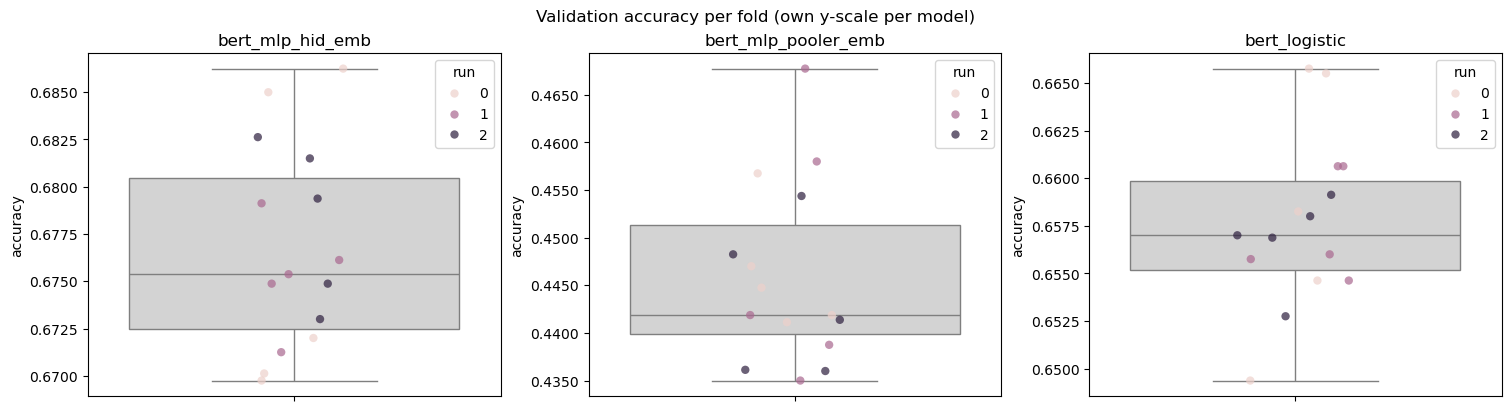

In [40]:
df = part1.analysis.make_data_frame(classifiers)
import seaborn as sns
from matplotlib.ticker import StrMethodFormatter

fig, axes = plt.subplots(1, len(model_names), figsize=(5 * len(model_names), 4), layout='constrained')
for a, model_name in zip(axes, model_names):
    sub = df[df['model'] == model_name]
    sns.boxplot(data=sub, y='accuracy', color='lightgray', showfliers=False, ax=a)
    sns.stripplot(data=sub, y='accuracy', hue='run', jitter=0.15, size=6, alpha=0.7, ax=a)
    a.set_title(model_name)
    a.yaxis.set_major_formatter(StrMethodFormatter("{x:.4f}"))
fig.suptitle('Validation accuracy per fold (own y-scale per model)')
plt.show()


A=bert_mlp_hid_emb B=bert_mlp_pooler_emb: P(A better) = 1.0000 P(tie) = 0.0000 P(B better) = 0.0000 effect size=-42.20
A=bert_mlp_hid_emb B=bert_logistic: P(A better) = 1.0000 P(tie) = 0.0000 P(B better) = 0.0000 effect size=-9.34
A=bert_mlp_pooler_emb B=bert_logistic: P(A better) = 0.0000 P(tie) = 0.0000 P(B better) = 1.0000 effect size=38.61


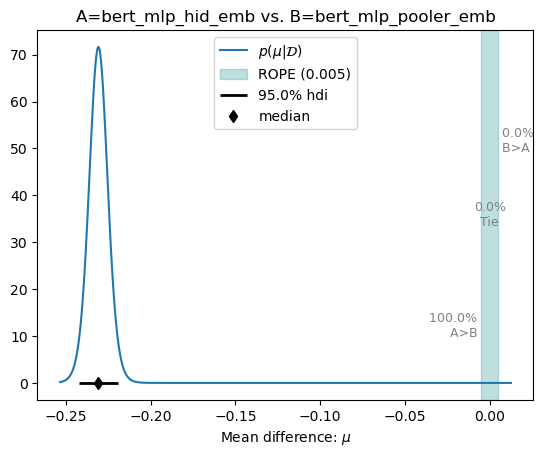

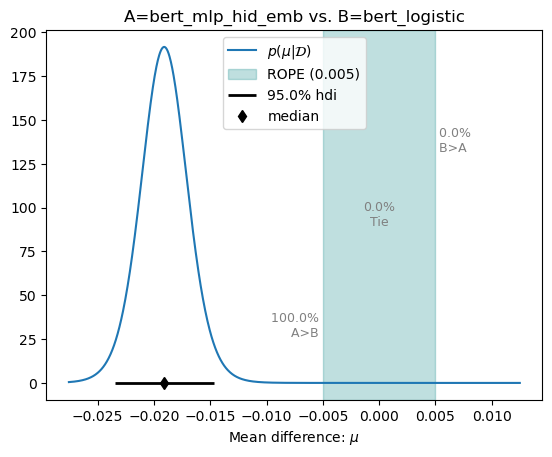

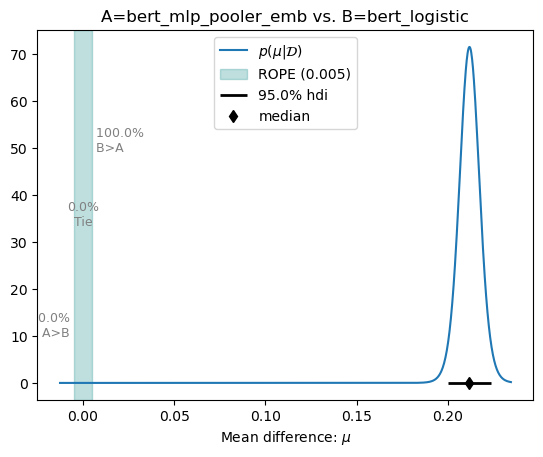

In [43]:
from itertools import combinations

def get_all_measurements_for(data, sys_name):
    return np.array([list(run['accuracies'].values()) for run in data[sys_name]])

ROPE = 0.005
for a, b in combinations(classifiers.keys(), 2):
    posterior = part1.analysis.BenavoliCorrelatedT(
      get_all_measurements_for(classifiers, a).flatten(),
      get_all_measurements_for(classifiers, b).flatten(),
      runs=len(seeds),
      names=[a, b],
    )
    p_a, p_tie, p_b = posterior.probs(ROPE)
    print(f"A={a} B={b}: P(A better) = {p_a:.4f} P(tie) = {p_tie:.4f} P(B better) = {p_b:.4f} effect size={posterior.effect_size:.2f}")
    posterior.plot(ROPE)


